# 03 — Visualizando Distribuições

No notebook 02 resumimos os dados com poucos números: média, mediana, desvio padrão, quartis. Mas números resumem **escondendo** coisas. Neste notebook vamos **olhar** os dados.

A **distribuição** de uma variável é a descrição de **quais valores ela assume e com que frequência**. É o conceito mais importante deste livro: na Parte II, as distribuições de probabilidade serão a versão "teórica" do que aqui vemos na prática.

Neste notebook vamos:
- Ver que distribuições **muito diferentes** podem ter a **mesma média e o mesmo desvio padrão**
- Construir **histogramas** e entender a escolha do número de faixas
- Suavizar o histograma com a **densidade (KDE)**
- Ler um **boxplot** e um **gráfico de violino**
- Conhecer a **função de distribuição acumulada empírica (ECDF)**
- Descobrir distribuições **bimodais** (com dois picos)
- "Desentortar" uma distribuição assimétrica com a **transformação logarítmica**

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

gorjetas = sns.load_dataset("tips")
gorjetas["percentual"] = gorjetas["tip"] / gorjetas["total_bill"] * 100
# dropna() remove as linhas com algum valor ausente (as 11 que vimos no notebook 01).
pinguins = sns.load_dataset("penguins").dropna()
print(f"Pinguins sem valores ausentes: {len(pinguins)}")

Pinguins sem valores ausentes: 333


## 2. Mesmos números, distribuições diferentes

Vamos criar quatro conjuntos de dados com **exatamente** a mesma média (50) e o mesmo desvio padrão (10), e olhar para eles.

In [2]:
rng = np.random.default_rng(42)
n = 2_000


def padronizar(valores, media=50, desvio=10):
    """Ajusta os valores para terem exatamente a média e o desvio padrão pedidos."""
    # (valores - média) / desvio deixa média 0 e desvio 1 (o "z-score", notebook 08); depois reescalamos.
    z = (valores - valores.mean()) / valores.std(ddof=1)
    return media + desvio * z


# np.concatenate junta dois vetores num só: aqui, dois "morros" separados formam uma distribuição bimodal.
conjuntos = {
    "Normal": padronizar(rng.normal(size=n)),
    "Uniforme": padronizar(rng.uniform(size=n)),
    "Bimodal": padronizar(np.concatenate([rng.normal(-2, 0.5, n // 2), rng.normal(2, 0.5, n // 2)])),
    "Assimétrica": padronizar(rng.exponential(size=n)),
}

# Os resumos numéricos: praticamente idênticos (média e desvio são iguais por construção).
pd.DataFrame({nome: pd.Series(v).describe() for nome, v in conjuntos.items()})

,Normal,Uniforme,Bimodal,Assimétrica
count,2000.000,2000.000,2000.000,2000.000
mean,50.000,50.000,50.000,50.000
std,10.000,10.000,10.000,10.000
min,14.141,32.954,32.799,39.725
25%,43.365,41.428,40.288,43.004
50%,50.326,50.057,48.850,46.871
75%,56.532,58.703,59.736,53.926
max,82.274,67.486,67.384,105.321


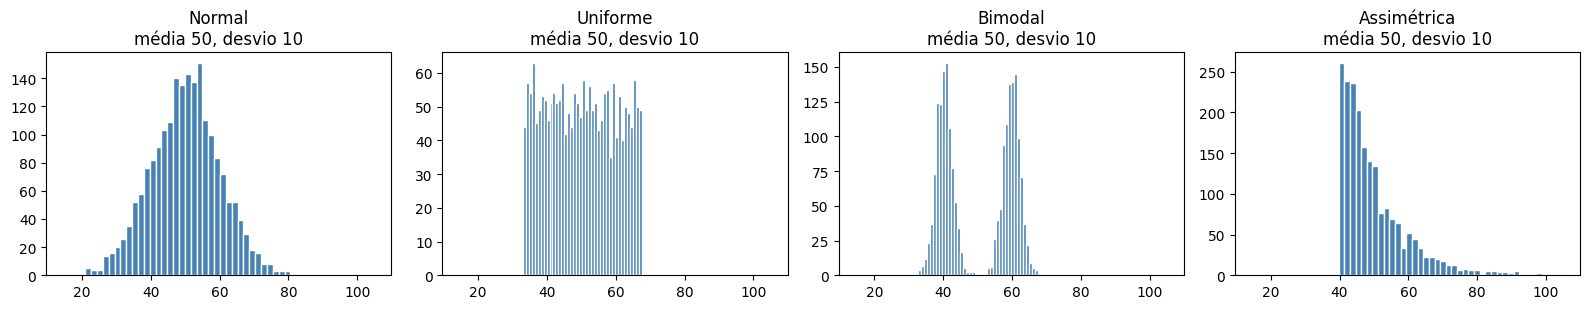

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharex=True)   # sharex: mesmo eixo x nos 4 gráficos
for ax, (nome, valores) in zip(axes, conjuntos.items()):
    ax.hist(valores, bins=40, color="steelblue", edgecolor="white")
    ax.set_title(f"{nome}\nmédia {valores.mean():.0f}, desvio {valores.std(ddof=1):.0f}")
plt.tight_layout()
plt.show()

**Conclusão:** os quatro conjuntos têm média **50** e desvio padrão **10**, mas são **completamente diferentes**:
- A **normal** é um sino simétrico, com valores de 14 a 82.
- A **uniforme** é "achatada": todos os valores entre 33 e 67 são igualmente comuns, e nada existe fora dessa faixa.
- A **bimodal** tem dois morros (perto de 40 e de 60) e um **vale vazio no meio**: a média, 50, é justamente um valor que **quase nunca aparece**. Aqui a média descreve muito mal um "valor típico".
- A **assimétrica** começa em 40, concentra-se perto dele e tem uma cauda que chega a **105**.

A lição: **sempre olhe os dados**. Dois números (média e desvio) não são suficientes para descrever uma distribuição.

## 🎓 Conceito: histograma

O **histograma** divide o eixo dos valores em **faixas** (*bins*) de mesma largura e desenha uma barra com a quantidade de valores em cada faixa. É a tabela de faixas do notebook 01 transformada em gráfico.

A escolha do **número de faixas** muda a história:
- **Poucas faixas:** o desenho fica grosseiro e esconde detalhes (como um segundo pico).
- **Muitas faixas:** cada faixa tem poucos valores, e o desenho fica cheio de "dentes" que são puro acaso.

Existem regras automáticas para escolher (como `bins="auto"`), mas vale sempre experimentar alguns valores.

Um detalhe útil: com `density=True`, a altura das barras é ajustada para que a **área total** do histograma seja 1. Assim, a área de cada barra é a **proporção** de valores naquela faixa, e histogramas de grupos de tamanhos diferentes ficam comparáveis.

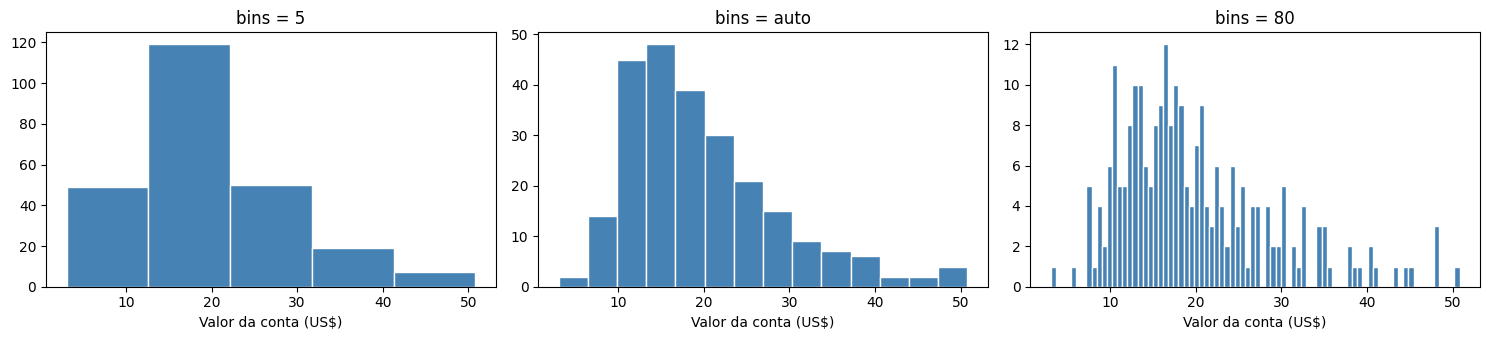

bins='auto' escolheu 14 faixas de largura 3.41 dólares


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, bins in zip(axes, [5, "auto", 80]):
    ax.hist(gorjetas["total_bill"], bins=bins, color="steelblue", edgecolor="white")
    ax.set_title(f"bins = {bins}")
    ax.set_xlabel("Valor da conta (US$)")
plt.tight_layout()
plt.show()

# np.histogram devolve as contagens e os limites das faixas, sem desenhar nada.
contagens, limites = np.histogram(gorjetas["total_bill"], bins="auto")
print(f"bins='auto' escolheu {len(contagens)} faixas de largura {limites[1] - limites[0]:.2f} dólares")

**Conclusão:** com **5 faixas** (esquerda), só vemos que há mais contas entre US\$ 10 e US\$ 20; a forma se perde. Com **80 faixas** (direita), cada faixa tem de 0 a 12 mesas, e o desenho fica cheio de buracos e picos que são puro acaso de quais mesas o garçom anotou. A escolha automática (centro) usou **14 faixas de US\$ 3,41** e mostra a forma com clareza: um pico entre US\$ 10 e US\$ 20 e uma cauda longa até US\$ 50, a assimetria à direita que medimos no notebook 02.

## 🎓 Conceito: densidade estimada (KDE)

A **estimativa de densidade por kernel** (KDE, de *kernel density estimation*) é um "histograma suavizado". A ideia: em cima de **cada valor** colocamos um pequeno "morrinho" (uma curva normal), e somamos todos os morrinhos. Onde há muitos valores próximos, os morrinhos se empilham e a curva fica alta.

A **largura de banda** (*bandwidth*) é a largura de cada morrinho, e tem o mesmo papel do número de faixas no histograma: morrinhos largos demais apagam detalhes, e estreitos demais deixam a curva cheia de picos falsos.

Como o histograma com `density=True`, a área sob a curva da KDE é 1.

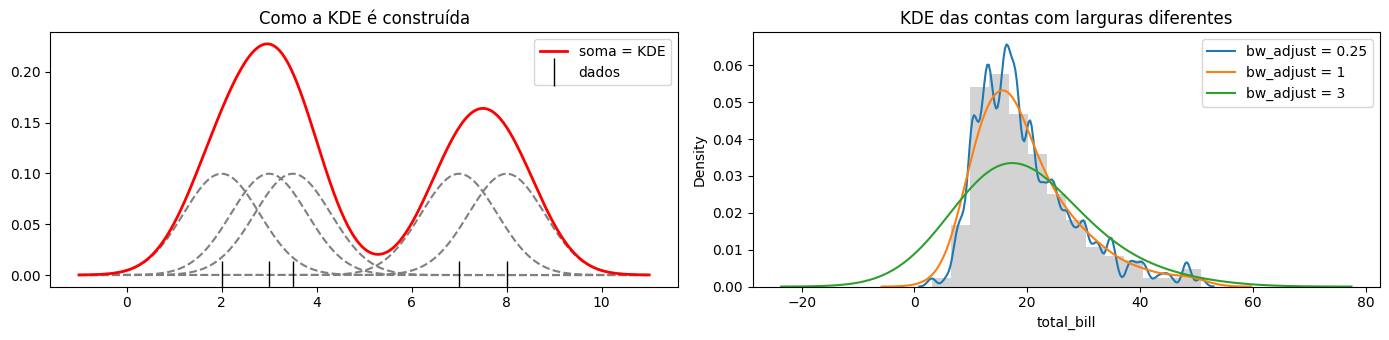

Área sob a KDE à mão: 1.000


In [5]:
# KDE "à mão" com poucos pontos, para ver os morrinhos se somando.
pontos = np.array([2.0, 3.0, 3.5, 7.0, 8.0])
eixo = np.linspace(-1, 11, 500)
largura = 0.8

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
soma = np.zeros_like(eixo)   # um vetor de zeros do mesmo tamanho do eixo, para acumular a soma
for p in pontos:
    # stats.norm.pdf é a curva normal (notebook 08) centrada em p; dividimos por 5 para a área total dar 1.
    morrinho = stats.norm.pdf(eixo, loc=p, scale=largura) / len(pontos)
    axes[0].plot(eixo, morrinho, color="gray", linestyle="--")
    soma += morrinho          # += acumula: soma = soma + morrinho
axes[0].plot(eixo, soma, color="red", linewidth=2, label="soma = KDE")
axes[0].plot(pontos, np.zeros_like(pontos), "k|", markersize=20, label="dados")   # "k|" = tracinhos pretos
axes[0].set_title("Como a KDE é construída")
axes[0].legend()

# Na prática, usamos o seaborn. bw_adjust multiplica a largura de banda escolhida automaticamente.
for ajuste in [0.25, 1, 3]:
    sns.kdeplot(gorjetas["total_bill"], bw_adjust=ajuste, ax=axes[1], label=f"bw_adjust = {ajuste}")
axes[1].hist(gorjetas["total_bill"], bins="auto", density=True, color="lightgray")
axes[1].set_title("KDE das contas com larguras diferentes")
axes[1].legend()
plt.tight_layout()
plt.show()

# Conferindo que a área sob a KDE construída à mão é 1: np.trapezoid soma a área sob a curva.
print(f"Área sob a KDE à mão: {np.trapezoid(soma, eixo):.3f}")

**Conclusão:** à esquerda, cada um dos 5 pontos ganha um morrinho (cinza tracejado), e a soma (vermelha) tem dois picos: um onde há três pontos próximos (2; 3; 3,5) e outro, mais baixo, onde há dois (7 e 8). A área sob a curva é **1,000**, como a de um histograma com `density=True`.

À direita, nas contas do tips, a largura importa muito: com `bw_adjust = 0,25` (azul) a curva fica cheia de picos que acompanham cada grupinho de mesas; com `bw_adjust = 3` (verde) ela fica achatada demais e **"vaza" para valores negativos**, prevendo contas abaixo de zero, que são impossíveis. A largura automática (`bw_adjust = 1`, laranja) acompanha bem o histograma cinza.

## 🎓 Conceito: boxplot

O **boxplot** (diagrama de caixa) desenha os números do notebook 02:
- A **caixa** vai de Q1 a Q3 (o IQR); a linha dentro dela é a **mediana**.
- Os **bigodes** vão até o valor mais extremo que **não** é outlier pela regra de 1,5 × IQR.
- Os **pontos** soltos são os **outliers**.

Ele perde detalhes da forma (um boxplot não mostra se há dois picos), mas é ótimo para **comparar muitos grupos** lado a lado. O **gráfico de violino** junta o boxplot com uma KDE espelhada, mostrando a forma também.

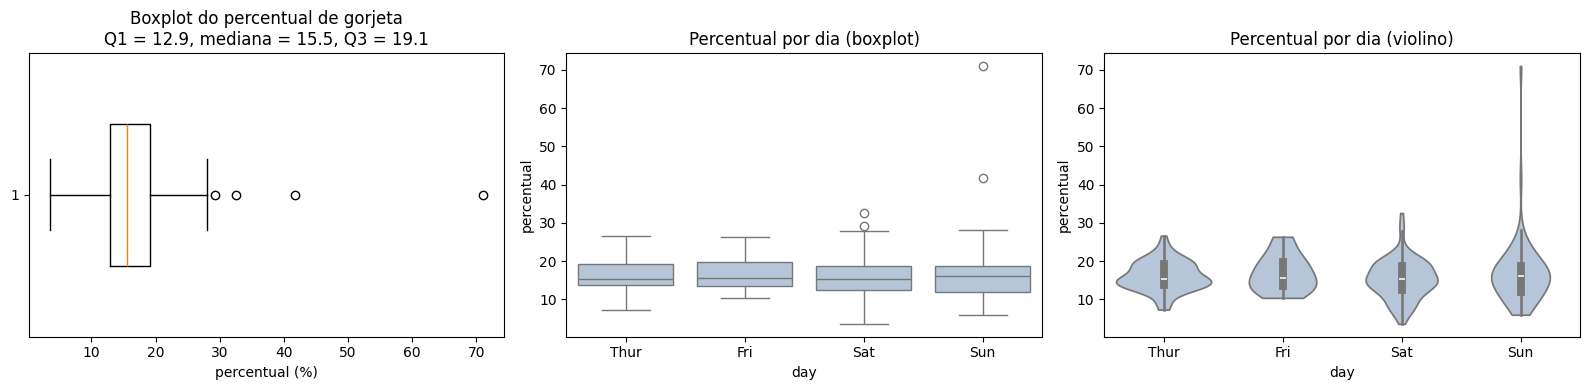

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Boxplot do percentual de gorjeta, com as partes anotadas.
valores = gorjetas["percentual"]
axes[0].boxplot(valores, vert=False, widths=0.5)   # vert=False deixa a caixa na horizontal
q1, mediana, q3 = np.quantile(valores, [0.25, 0.5, 0.75])
# "\n" dentro do texto quebra a linha do título.
axes[0].set_title(f"Boxplot do percentual de gorjeta\nQ1 = {q1:.1f}, mediana = {mediana:.1f}, Q3 = {q3:.1f}")
axes[0].set_xlabel("percentual (%)")

# Comparando grupos: seaborn faz um boxplot por categoria.
sns.boxplot(data=gorjetas, x="day", y="percentual", ax=axes[1], color="lightsteelblue")
axes[1].set_title("Percentual por dia (boxplot)")

sns.violinplot(data=gorjetas, x="day", y="percentual", ax=axes[2], color="lightsteelblue", cut=0)
axes[2].set_title("Percentual por dia (violino)")
plt.tight_layout()
plt.show()

**Conclusão:** - **Boxplot à esquerda:** a caixa vai de **12,9%** (Q1) a **19,1%** (Q3), com a mediana em **15,5%**. Os quatro pontos à direita são exatamente os **4 outliers** que a regra do IQR encontrou no notebook 02, com a mesa de 71% bem isolada.
- **Por dia (centro):** as medianas e as caixas são muito parecidas nos quatro dias; o que muda são os outliers, que só aparecem no sábado e no domingo.
- **Violino (direita):** mostra a mesma coisa com a forma da distribuição. O violino do domingo tem uma "agulha" comprida até 71%, causada por uma única mesa. Sem essa mesa, o violino de domingo teria a mesma altura dos outros: um grupo que parece "diferente" pode ser só **um** outlier.

## 🎓 Conceito: função de distribuição acumulada empírica (ECDF)

A **ECDF** responde, para cada valor $x$: **que proporção dos dados é menor ou igual a $x$?**

$$F(x) = \frac{\text{quantidade de valores} \le x}{n}$$

Ela sobe em "degraus" de 0 até 1. Duas vantagens sobre o histograma:
- **Não tem parâmetros para escolher** (nada de número de faixas ou largura de banda): todos os dados aparecem.
- Permite **ler quantis diretamente**: onde a curva cruza 0,5 está a mediana; onde cruza 0,9 está o percentil 90.

Ela é a versão "observada" da **função de distribuição acumulada (CDF)**, que veremos no notebook 08.

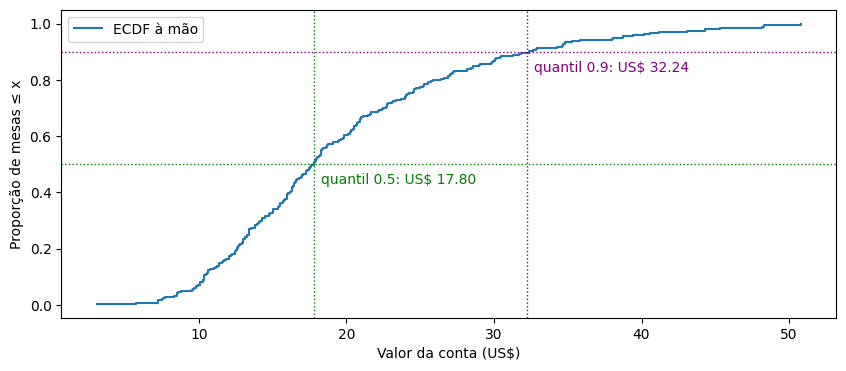

Contas de até US$ 20: 60.2%
Contas acima de US$ 40: 4.1%


In [7]:
# ECDF "à mão": ordenar os valores e associar a cada um a proporção acumulada 1/n, 2/n, ..., n/n.
x_ordenado = np.sort(gorjetas["total_bill"])
proporcao = np.arange(1, len(x_ordenado) + 1) / len(x_ordenado)   # arange(1, n+1) = 1, 2, ..., n

fig, ax = plt.subplots(figsize=(10, 4))
ax.step(x_ordenado, proporcao, where="post", label="ECDF à mão")   # step desenha degraus
for q, cor in [(0.5, "green"), (0.9, "purple")]:
    valor = np.quantile(gorjetas["total_bill"], q)
    ax.axhline(q, color=cor, linestyle=":", linewidth=1)
    ax.axvline(valor, color=cor, linestyle=":", linewidth=1)
    ax.annotate(f"quantil {q}: US$ {valor:.2f}", xy=(valor + 0.5, q - 0.07), color=cor)
ax.set_xlabel("Valor da conta (US$)")
ax.set_ylabel("Proporção de mesas ≤ x")
ax.legend()
plt.show()

# Perguntas respondidas pela ECDF: qual a proporção de contas até US$ 20? E acima de US$ 40?
contas = gorjetas["total_bill"]
print(f"Contas de até US$ 20: {np.mean(contas <= 20):.1%}")
print(f"Contas acima de US$ 40: {np.mean(contas > 40):.1%}")

**Conclusão:** a ECDF cruza **0,5** em **US\$ 17,80** (a mediana do notebook 02) e **0,9** em **US\$ 32,24** (o percentil 90). Ela é mais íngreme entre US\$ 10 e US\$ 25, onde se concentra a maioria das mesas, e quase plana acima de US\$ 35, onde há poucas.

Com ela respondemos perguntas de proporção sem nenhum cálculo extra: **60,2%** das contas são de até US\$ 20, e só **4,1%** passam de US\$ 40.

## 3. Distribuições bimodais: quando há grupos escondidos

Uma distribuição com **dois picos** (bimodal) é um aviso: provavelmente estamos misturando **grupos diferentes**. Vamos olhar o comprimento da nadadeira (*flipper*) dos pinguins.

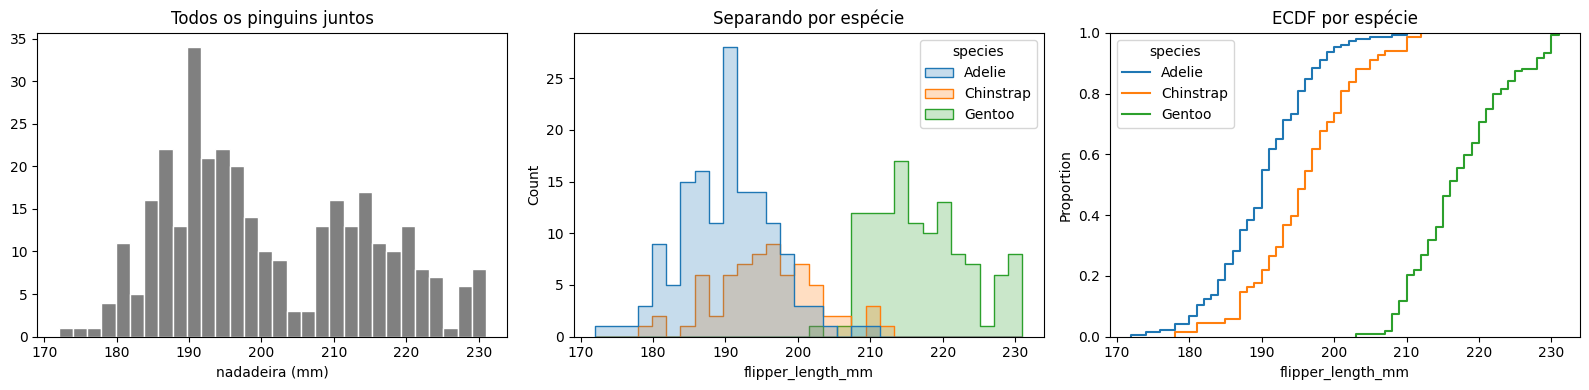

Média geral: 201.0 mm


,count,mean,std
species,,,
Adelie,146,190.103,6.522
Chinstrap,68,195.824,7.132
Gentoo,119,217.235,6.585


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(pinguins["flipper_length_mm"], bins=30, color="gray", edgecolor="white")
axes[0].set_title("Todos os pinguins juntos")
axes[0].set_xlabel("nadadeira (mm)")

# hue="species" pinta cada espécie de uma cor; element="step" desenha só o contorno.
sns.histplot(data=pinguins, x="flipper_length_mm", hue="species", bins=30, element="step", ax=axes[1])
axes[1].set_title("Separando por espécie")

# ECDF de cada espécie: o seaborn faz a conta por nós.
sns.ecdfplot(data=pinguins, x="flipper_length_mm", hue="species", ax=axes[2])
axes[2].set_title("ECDF por espécie")
plt.tight_layout()
plt.show()

media_geral = pinguins["flipper_length_mm"].mean()
print(f"Média geral: {media_geral:.1f} mm")
pinguins.groupby("species")["flipper_length_mm"].agg(["count", "mean", "std"])

**Conclusão:** o histograma de todos os pinguins juntos (esquerda) tem **dois picos**, um perto de 190 mm e outro perto de 215 mm, e a média geral (**201 mm**) cai justamente no **vale** entre eles. Separar por espécie (centro) explica tudo: os pinguins **Gentoo** têm nadadeiras bem maiores (média de **217,2 mm**) que os **Adelie** (190,1 mm) e os **Chinstrap** (195,8 mm), que se sobrepõem bastante.

Na ECDF por espécie (direita), a curva do Gentoo está deslocada para a direita: praticamente todos os Gentoo têm nadadeiras maiores que 205 mm, enquanto quase todos os Adelie ficam abaixo disso.

Repare também no desvio padrão: dentro de cada espécie ele fica entre **6,5** e **7,1 mm**, bem menor que a dispersão de todos juntos. Grande parte da variação da nadadeira é explicada pela espécie. Essa ideia de "uma variável explica parte da variação de outra" é a base dos modelos de ML e voltará na regressão (notebook 14).

🔗 **Ponte para o ML:** um classificador poderia usar a nadadeira para separar os Gentoo das outras espécies quase sem erro, mas teria dificuldade para separar Adelie de Chinstrap.

## 🎓 Conceito: transformação logarítmica

Variáveis com **forte assimetria à direita** (preços, rendas, populações) têm a maioria dos valores amontoada à esquerda e uma cauda longa à direita. O **logaritmo** "comprime" os valores grandes muito mais do que os pequenos:

| x | 1 | 10 | 100 | 1.000 |
|---|---|---|---|---|
| log₁₀(x) | 0 | 1 | 2 | 3 |

De 1 para 10 e de 100 para 1.000, o log sobe o mesmo **1 ponto**: ele transforma **multiplicações** em **somas**. Isso costuma deixar distribuições assimétricas bem mais **simétricas**. (Usaremos o log natural, `np.log`, de base $e \approx 2{,}718$; a forma resultante é a mesma, só muda a escala.)

🔗 **Ponte para o ML:** no ML-01, colunas assimétricas como população e cômodos foram transformadas com log, o que ajudou a regressão linear. Modelos lineares e métodos baseados em distância costumam funcionar melhor com variáveis mais simétricas.

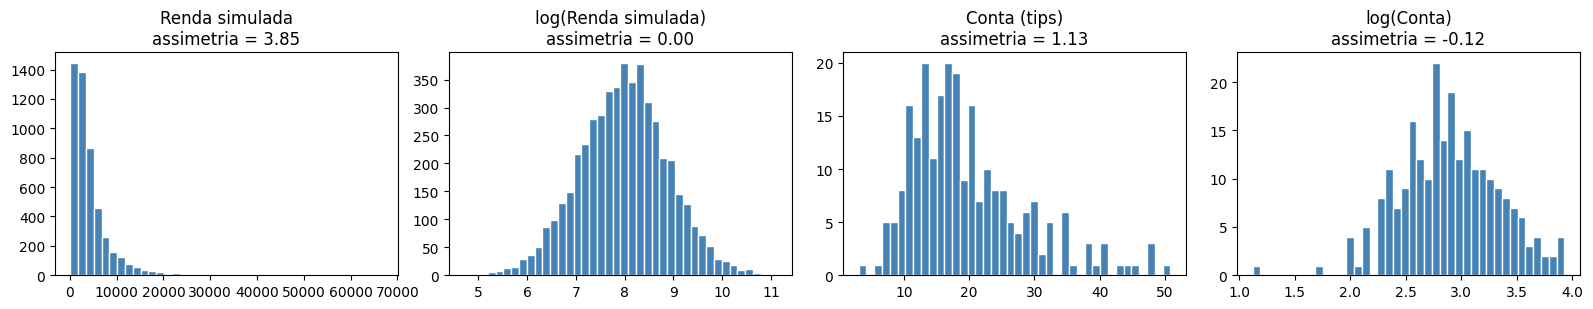

In [9]:
# Uma variável fortemente assimétrica: rendas simuladas com a distribuição log-normal (notebook 08).
rng = np.random.default_rng(42)
renda = rng.lognormal(mean=8, sigma=0.9, size=5_000)

variaveis = {
    "Renda simulada": renda,
    "log(Renda simulada)": np.log(renda),
    "Conta (tips)": gorjetas["total_bill"].to_numpy(),
    "log(Conta)": np.log(gorjetas["total_bill"].to_numpy()),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (nome, valores) in zip(axes, variaveis.items()):
    ax.hist(valores, bins=40, color="steelblue", edgecolor="white")
    ax.set_title(f"{nome}\nassimetria = {stats.skew(valores):.2f}")
plt.tight_layout()
plt.show()

**Conclusão:** a renda simulada tem assimetria **3,85**: quase todos os valores se espremem à esquerda, e a cauda chega a quase 70 mil. Depois do log, a assimetria cai para **0,00** e o histograma vira um sino simétrico. Isso acontece porque essa renda foi gerada como o exponencial de uma normal (a distribuição log-normal), e o log desfaz exatamente essa transformação.

Nas contas do tips, a assimetria cai de **1,13** para **−0,12**: o log corrige quase toda a assimetria, e até passa um pouco do ponto, deixando uma leve cauda para a esquerda (as contas muito baixas, como a de US\$ 3,07, viram valores bem baixos de log).

## 4. Resumo e próximos passos

| Gráfico | Mostra bem | Cuidado com |
|---|---|---|
| Histograma | forma, picos, caudas | número de faixas |
| KDE | forma suave, comparação de grupos | largura de banda; pode "vazar" para valores impossíveis |
| Boxplot | mediana, IQR, outliers, muitos grupos | esconde picos múltiplos |
| Violino | forma + resumo por grupo | mesma escolha de largura da KDE |
| ECDF | todos os dados, quantis, proporções | menos intuitiva no começo |

**Conceitos que você aprendeu**
- **Distribuição** de uma variável e por que os resumos numéricos não bastam.
- **Histograma** (e `density=True`), **KDE** (e a largura de banda), **boxplot**, **violino** e **ECDF**.
- Distribuições **bimodais** como sinal de grupos misturados.
- A **transformação logarítmica** para reduzir a assimetria.

**Python novo:** `def` com valores padrão, `np.concatenate`, `sharex`, `np.histogram`, `np.zeros_like`, `+=`, `np.trapezoid`, `sns.kdeplot` / `boxplot` / `violinplot` / `histplot` / `ecdfplot`, o parâmetro `hue`, `ax.step`, `ax.annotate`, `np.arange`, `np.log`, `.dropna()`.

**Próximo notebook:** até aqui olhamos **uma variável de cada vez**. No notebook 04 vamos estudar **relações entre duas variáveis**: a conta e a gorjeta andam juntas? Vamos medir isso com a **covariância** e a **correlação**, e descobrir armadilhas famosas como o **paradoxo de Simpson**.